# Redes neuronales con PyTorch paso a paso

En la comparación oficial (`reports/benchmark.csv`) la red neuronal quedó
**última**: el `MLPClassifier` de scikit-learn sacó AUROC 0,635 con la rejilla
del protocolo y 0,650 con la rejilla ampliada de `experiments.py`, frente a
0,661 de CatBoost.

Este notebook es una **alternativa independiente**: entrena las redes a mano
con PyTorch para tener control de todo lo que scikit-learn esconde
(arquitectura, dropout, batch normalization, optimizador, early stopping,
scheduler) y ver, paso a paso, si alguna combinación cierra la brecha.

**Reglas (las mismas del protocolo, `docs/protocolo-evaluacion.md`):**

- La misma partición 80 / 20 de `split_data`. **El 20 % de prueba no se usa
  aquí**: se borra apenas se crea.
- El escalado se aprende solo con los datos de entrenamiento de cada partición.
- Las mismas métricas: AUROC (principal), AUPRC, Brier y la recta de
  calibración (`calibration_line` de `train.py`).
- Las mismas 5 particiones externas de `evaluate_model`, para que el número
  final sea comparable con el benchmark.

**Ruta del notebook**

| Paso | Qué se hace |
|---|---|
| 0 | Interruptores |
| 1 | Librerías, semilla y dispositivo |
| 2 | Datos: entrenamiento / validación (la prueba no se toca) |
| 3 | Escalado y tensores |
| 4 | Cuatro tipos de red |
| 5 | El ciclo de entrenamiento, con early stopping |
| 6 | Entrenar una red y leer sus curvas |
| 7 | Comparar los cuatro tipos de red |
| 8 | Un hiperparámetro a la vez |
| 9 | Búsqueda aleatoria combinando hiperparámetros |
| 10 | Validación cruzada 5 particiones de las mejores configuraciones |
| 11 | (Opcional) Validación anidada: el número honesto |
| 12 | Comparación con el benchmark y conclusiones |

## Paso 0. Interruptores

- `RAPIDO = True` baja las épocas y el número de pruebas, para revisar que todo
  corre en unos 4 minutos. Con `False` hace la exploración completa
  (unos 13 minutos en un MacBook, solo CPU, incluido el paso 11).
- `VALIDACION_ANIDADA = False` se salta el paso 11 (el más caro, unos 5 minutos).
- `GUARDAR = True` escribe los resultados en `reports/pytorch_experiments.csv`.

In [1]:
RAPIDO = False
VALIDACION_ANIDADA = True
GUARDAR = True

## Paso 1. Librerías, semilla y dispositivo

PyTorch no viene en las dependencias base del proyecto. Se instala con el grupo
`nn` de `pyproject.toml`:

```bash
uv sync --group nn
```

**Semilla.** Una red empieza con pesos al azar y baraja los datos en cada
época; sin fijar la semilla, dos corridas iguales dan números distintos.
`fijar_semilla` fija Python, NumPy y PyTorch con `RANDOM_STATE = 42`.

**Dispositivo.** Con 17 variables y redes de pocos miles de pesos, la CPU es
igual o más rápida que una GPU (mover cada lote a la GPU cuesta más que la
cuenta). Por eso se usa CPU; para probar GPU basta cambiar `DEVICE`.

In [2]:
# El paquete bolsalab vive en la raíz del repositorio, un nivel arriba de notebooks/.
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import copy
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from torch import nn

from bolsalab.config import RANDOM_STATE, REPORTS_DIR
from bolsalab.features import FEATURES, TRAINING_FILE
from bolsalab.modeling.train import build_training_table, calibration_line, split_data

RESULTS_FILE = REPORTS_DIR / "pytorch_experiments.csv"
DEVICE = torch.device("cpu")  # "mps" en Mac con Apple Silicon, "cuda" con GPU NVIDIA


def fijar_semilla(semilla: int = RANDOM_STATE) -> None:
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)


fijar_semilla()
print(f"PyTorch {torch.__version__} · dispositivo: {DEVICE} · hilos: {torch.get_num_threads()}")

PyTorch 2.15.0 · dispositivo: cpu · hilos: 6


## Paso 2. Datos: entrenamiento, validación y prueba

Se parte de la misma tabla que usa `train.py` (54.704 personas, 17 variables,
objetivo `sold`) y de la misma partición `split_data`.

Una red necesita **tres** grupos de datos, no dos:

| Grupo | Para qué | Tamaño |
|---|---|---|
| Ajuste (`fit`) | La red aprende los pesos | 64 % |
| Validación (`val`) | Decide cuándo parar (early stopping) y compara configuraciones | 16 % |
| Prueba (`test`) | Medición final, una sola vez. **No se usa en este notebook** | 20 % |

La validación sale del 80 % de entrenamiento, estratificada para conservar el
19,9 % de ventas.

In [3]:
if not TRAINING_FILE.exists():
    print("No existe la tabla de entrenamiento; la construyo con features.py...")
    build_training_table()

table = pd.read_parquet(TRAINING_FILE)
X_train, X_test, y_train, y_test = split_data(table)
del X_test, y_test  # la prueba final no se usa aquí

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE)

pd.DataFrame(
    {
        "Personas": [len(X_fit), len(X_val), len(X_train)],
        "Vendieron": [f"{y.mean():.2%}" for y in (y_fit, y_val, y_train)],
    },
    index=["Ajuste (fit)", "Validación (val)", "Total entrenamiento (80 %)"],
)

,Personas,Vendieron
Ajuste (fit),35010,19.87%
Validación (val),8753,19.87%
Total entrenamiento (80 %),43763,19.87%


## Paso 3. Escalado y tensores

La red aprende con gradientes: si una variable va de 0 a 1 y otra
(`age_squared`) llega a miles, los pasos de aprendizaje quedan dominados por la
grande. `StandardScaler` deja cada variable con media 0 y desviación 1.

El escalador se ajusta **solo con `X_fit`** y después se aplica a `X_val`; si
se ajustara con todo, la validación filtraría información al entrenamiento.

PyTorch trabaja con `torch.Tensor`, no con DataFrames: `a_tensores` hace las
dos cosas.

In [4]:
def a_tensores(X_aprende, y_aprende, X_aplica, y_aplica):
    # Escala con lo aprendido en X_aprende y devuelve los cuatro tensores float32.
    scaler = StandardScaler().fit(X_aprende)

    def x(X):
        return torch.tensor(scaler.transform(X), dtype=torch.float32, device=DEVICE)

    def y(v):
        return torch.tensor(np.asarray(v), dtype=torch.float32, device=DEVICE)

    return x(X_aprende), y(y_aprende), x(X_aplica), y(y_aplica)


Xf, yf, Xv, yv = a_tensores(X_fit, y_fit, X_val, y_val)
print(f"X_fit: {tuple(Xf.shape)} · X_val: {tuple(Xv.shape)}")
pd.DataFrame(
    {"media (fit)": Xf.mean(0).cpu(), "desv. (fit)": Xf.std(0).cpu(),
     "media (val)": Xv.mean(0).cpu(), "desv. (val)": Xv.std(0).cpu()},
    index=FEATURES,
).round(2)

X_fit: (35010, 17) · X_val: (8753, 17)


,media (fit),desv. (fit),media (val),desv. (val)
knows_interest,-0.0,1.0,-0.01,1.01
knows_inflation,0.0,1.0,-0.01,1.01
knows_diversification,-0.0,1.0,-0.00,1.00
knowledge_confidence,-0.0,1.0,-0.02,1.00
overconfidence,0.0,1.0,-0.00,1.00
age,0.0,1.0,-0.02,1.00
age_squared,0.0,1.0,-0.02,1.00
male,0.0,1.0,0.00,1.00
university,-0.0,1.0,0.01,1.00
married,0.0,1.0,-0.02,1.01


## Paso 4. Cuatro tipos de red

Todas reciben las 17 variables y devuelven **un logit** por persona (un número
real; la probabilidad de vender es `sigmoid(logit)`). Devolver logits y no
probabilidades es lo normal en PyTorch, porque `BCEWithLogitsLoss` combina el
sigmoide y la pérdida de forma numéricamente estable.

| Tipo | Idea | Por qué probarla |
|---|---|---|
| `logistica` | Una sola capa lineal, sin capas ocultas | Es la regresión logística escrita en PyTorch. Sirve de control: debe dar ≈ 0,646 como en el benchmark. Si no, el ciclo de entrenamiento está mal |
| `mlp` | Capas ocultas `Lineal → (BatchNorm) → activación → (Dropout)` | La red clásica, la misma idea del `MLPClassifier` |
| `resmlp` | MLP con conexiones residuales: cada bloque suma su entrada a su salida | Los atajos ayudan a que el gradiente llegue a las primeras capas en redes más profundas |
| `wide_deep` | Una parte lineal ("ancha") más un MLP ("profunda"), sumadas | La parte lineal captura los efectos simples, que en este cuestionario pesan mucho; el MLP solo tiene que aprender lo que falta |

`bloque` es la pieza que repiten las tres redes con capas ocultas.
`**_` en cada constructor deja pasar el diccionario de configuración completo
e ignora lo que esa red no usa.

In [5]:
ACTIVACIONES = {"relu": nn.ReLU, "gelu": nn.GELU, "silu": nn.SiLU, "tanh": nn.Tanh}


def bloque(n_in, n_out, activacion="relu", dropout=0.0, batchnorm=False):
    capas = [nn.Linear(n_in, n_out)]
    if batchnorm:
        capas.append(nn.BatchNorm1d(n_out))
    capas.append(ACTIVACIONES[activacion]())
    if dropout > 0:
        capas.append(nn.Dropout(dropout))
    return nn.Sequential(*capas)


class Logistica(nn.Module):
    def __init__(self, n_in, **_):
        super().__init__()
        self.lineal = nn.Linear(n_in, 1)

    def forward(self, x):
        return self.lineal(x).squeeze(-1)


class MLP(nn.Module):
    def __init__(self, n_in, capas=(32, 16), activacion="relu", dropout=0.0, batchnorm=False, **_):
        super().__init__()
        tamanos = [n_in, *capas]
        self.oculta = nn.Sequential(*[
            bloque(a, b, activacion, dropout, batchnorm) for a, b in zip(tamanos[:-1], tamanos[1:])
        ])
        self.salida = nn.Linear(tamanos[-1], 1)

    def forward(self, x):
        return self.salida(self.oculta(x)).squeeze(-1)


class BloqueResidual(nn.Module):
    # x -> activación(x + F(x)): si F no aporta, el bloque puede aprender F ≈ 0 y dejar pasar x.
    def __init__(self, ancho, activacion, dropout, batchnorm):
        super().__init__()
        self.f = nn.Sequential(bloque(ancho, ancho, activacion, dropout, batchnorm),
                               nn.Linear(ancho, ancho))
        self.activacion = ACTIVACIONES[activacion]()

    def forward(self, x):
        return self.activacion(x + self.f(x))


class ResMLP(nn.Module):
    def __init__(self, n_in, ancho=32, n_bloques=2, activacion="relu", dropout=0.0,
                 batchnorm=False, **_):
        super().__init__()
        self.entrada = bloque(n_in, ancho, activacion, 0.0, batchnorm)
        self.bloques = nn.Sequential(*[
            BloqueResidual(ancho, activacion, dropout, batchnorm) for _ in range(n_bloques)
        ])
        self.salida = nn.Linear(ancho, 1)

    def forward(self, x):
        return self.salida(self.bloques(self.entrada(x))).squeeze(-1)


class WideDeep(nn.Module):
    def __init__(self, n_in, capas=(32, 16), activacion="relu", dropout=0.0, batchnorm=False, **_):
        super().__init__()
        self.ancha = nn.Linear(n_in, 1)
        self.profunda = MLP(n_in, capas, activacion, dropout, batchnorm)

    def forward(self, x):
        return self.ancha(x).squeeze(-1) + self.profunda(x)


ARQUITECTURAS = {"logistica": Logistica, "mlp": MLP, "resmlp": ResMLP, "wide_deep": WideDeep}


def contar_pesos(modelo):
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)

In [6]:
# Cada red con su configuración por defecto: estructura y número de pesos.
for nombre, Clase in ARQUITECTURAS.items():
    modelo = Clase(len(FEATURES))
    print(f"=== {nombre}: {contar_pesos(modelo):,} pesos ===")
    print(modelo, end="\n\n")

=== logistica: 18 pesos ===
Logistica(
  (lineal): Linear(in_features=17, out_features=1, bias=True)
)

=== mlp: 1,121 pesos ===
MLP(
  (oculta): Sequential(
    (0): Sequential(
      (0): Linear(in_features=17, out_features=32, bias=True)
      (1): ReLU()
    )
    (1): Sequential(
      (0): Linear(in_features=32, out_features=16, bias=True)
      (1): ReLU()
    )
  )
  (salida): Linear(in_features=16, out_features=1, bias=True)
)

=== resmlp: 4,833 pesos ===
ResMLP(
  (entrada): Sequential(
    (0): Linear(in_features=17, out_features=32, bias=True)
    (1): ReLU()
  )
  (bloques): Sequential(
    (0): BloqueResidual(
      (f): Sequential(
        (0): Sequential(
          (0): Linear(in_features=32, out_features=32, bias=True)
          (1): ReLU()
        )
        (1): Linear(in_features=32, out_features=32, bias=True)
      )
      (activacion): ReLU()
    )
    (1): BloqueResidual(
      (f): Sequential(
        (0): Sequential(
          (0): Linear(in_features=32, out_fe

## Paso 5. El ciclo de entrenamiento

Entrenar una red es repetir, lote por lote, cinco pasos:

1. `optimizador.zero_grad()`: borra los gradientes del lote anterior.
2. `logits = modelo(xb)`: **forward**, la red predice.
3. `perdida(logits, yb)`: compara con la respuesta real (entropía cruzada binaria).
4. `loss.backward()`: **backpropagation**, calcula cuánto cambiar cada peso.
5. `optimizador.step()`: mueve los pesos en esa dirección.

Una **época** es una pasada completa por `X_fit`. Al final de cada época se mide
el AUROC en validación, y entran tres mecanismos:

- **Early stopping:** si el AUROC de validación no mejora en `paciencia`
  épocas seguidas, se para y se recuperan los pesos de la mejor época. Es la
  principal defensa contra el sobreajuste.
- **Scheduler (`ReduceLROnPlateau`):** si el AUROC se estanca 3 épocas, la tasa
  de aprendizaje se divide por 2, para afinar con pasos más pequeños.
- **`modelo.train()` / `modelo.eval()`:** dropout y batch norm se comportan
  distinto al entrenar y al predecir; olvidar `eval()` da predicciones ruidosas.

**`BASE`** es la configuración de partida. Cada experimento cambia solo las
llaves que le interesan; el resto sale de aquí.

| Hiperparámetro | Qué controla |
|---|---|
| `arquitectura`, `capas`, `ancho`, `n_bloques` | Tipo y tamaño de la red |
| `activacion` | La no linealidad entre capas |
| `dropout` | Fracción de neuronas que se apagan al azar en cada lote (regularización) |
| `batchnorm` | Normaliza la salida de cada capa por lote |
| `optimizador`, `lr` | Cómo y cuánto se mueven los pesos en cada paso |
| `weight_decay` | Penaliza pesos grandes (regularización L2, el `alpha` de scikit-learn) |
| `batch_size` | Personas por lote: lotes chicos dan pasos ruidosos, lotes grandes pasos estables |
| `pos_weight` | Peso extra de los que vendieron en la pérdida (para el desbalance 80 / 20) |
| `epocas`, `paciencia` | Máximo de épocas y cuántas tolerar sin mejora |

In [7]:
BASE = {
    "arquitectura": "mlp",
    "capas": (32, 16),       # mlp y wide_deep
    "ancho": 32,             # resmlp
    "n_bloques": 2,          # resmlp
    "activacion": "relu",
    "dropout": 0.1,
    "batchnorm": False,
    "optimizador": "adam",
    "lr": 1e-3,
    "weight_decay": 1e-4,
    "batch_size": 256,
    "pos_weight": 1.0,
    "epocas": 30 if RAPIDO else 100,
    "paciencia": 5 if RAPIDO else 10,
    "scheduler": True,
}

OPTIMIZADORES = {
    "adam": lambda p, c: torch.optim.Adam(p, lr=c["lr"], weight_decay=c["weight_decay"]),
    "adamw": lambda p, c: torch.optim.AdamW(p, lr=c["lr"], weight_decay=c["weight_decay"]),
    "sgd": lambda p, c: torch.optim.SGD(p, lr=c["lr"], momentum=0.9, nesterov=True,
                                        weight_decay=c["weight_decay"]),
}


@torch.no_grad()
def predecir(modelo, X):
    # Probabilidad de vender para cada fila de X.
    modelo.eval()
    return torch.sigmoid(modelo(X)).cpu().numpy()


def metricas(y, p):
    # Las métricas del protocolo (las mismas que SCORERS en train.py).
    y = np.asarray(y)
    intercepto, pendiente = calibration_line(y, p)
    return {
        "auroc": roc_auc_score(y, p),
        "auprc": average_precision_score(y, p),
        "brier": brier_score_loss(y, p),
        "calibration_intercept": intercepto,
        "calibration_slope": pendiente,
    }


def entrenar(cfg, X_fit, y_fit, X_val, y_val, semilla=RANDOM_STATE):
    # Entrena una red con early stopping. Devuelve (modelo con los mejores pesos, historia).
    cfg = {**BASE, **cfg}
    fijar_semilla(semilla)
    modelo = ARQUITECTURAS[cfg["arquitectura"]](X_fit.shape[1], **cfg).to(DEVICE)
    optimizador = OPTIMIZADORES[cfg["optimizador"]](modelo.parameters(), cfg)
    scheduler = (torch.optim.lr_scheduler.ReduceLROnPlateau(optimizador, mode="max",
                                                            factor=0.5, patience=3)
                 if cfg["scheduler"] else None)
    perdida = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(cfg["pos_weight"], device=DEVICE))
    y_val_np = y_val.cpu().numpy()

    historia, mejor_auc, mejor_estado, sin_mejora = [], -np.inf, None, 0
    n = len(X_fit)
    for epoca in range(1, cfg["epocas"] + 1):
        # --- entrenamiento: una pasada por todos los lotes ---
        modelo.train()
        orden = torch.randperm(n, device=DEVICE)
        suma_perdida = 0.0
        for inicio in range(0, n, cfg["batch_size"]):
            idx = orden[inicio:inicio + cfg["batch_size"]]
            if len(idx) < 2:  # batch norm no funciona con un lote de una sola persona
                continue
            optimizador.zero_grad()                       # 1
            logits = modelo(X_fit[idx])                   # 2
            loss = perdida(logits, y_fit[idx])            # 3
            loss.backward()                               # 4
            optimizador.step()                            # 5
            suma_perdida += loss.item() * len(idx)

        # --- validación: AUROC y pérdida con los pesos de esta época ---
        modelo.eval()
        with torch.no_grad():
            logits_val = modelo(X_val)
            perdida_val = perdida(logits_val, y_val).item()
        auc_val = roc_auc_score(y_val_np, torch.sigmoid(logits_val).cpu().numpy())
        historia.append({"epoca": epoca, "perdida_fit": suma_perdida / n,
                         "perdida_val": perdida_val, "auroc_val": auc_val,
                         "lr": optimizador.param_groups[0]["lr"]})

        if scheduler:
            scheduler.step(auc_val)
        if auc_val > mejor_auc + 1e-4:
            mejor_auc, mejor_estado, sin_mejora = auc_val, copy.deepcopy(modelo.state_dict()), 0
        else:
            sin_mejora += 1
            if sin_mejora >= cfg["paciencia"]:
                break

    modelo.load_state_dict(mejor_estado)
    return modelo, pd.DataFrame(historia)


def probar(cfg, etiqueta=""):
    # Entrena con (Xf, yf), mide en (Xv, yv) y devuelve una fila de resultados.
    cfg = {**BASE, **cfg}
    inicio = time.perf_counter()
    modelo, historia = entrenar(cfg, Xf, yf, Xv, yv)
    fila = {
        "etiqueta": etiqueta,
        **metricas(y_val, predecir(modelo, Xv)),
        "mejor_epoca": int(historia["auroc_val"].idxmax()) + 1,
        "epocas": len(historia),
        "pesos": contar_pesos(modelo),
        "segundos": round(time.perf_counter() - inicio, 1),
        "cfg": cfg,
    }
    return fila, modelo, historia

## Paso 6. Entrenar una red y leer sus curvas

Antes de comparar nada, conviene entrenar **una** red (`BASE`: MLP de 32 y 16
neuronas) y mirar cómo aprende. Las curvas dicen más que el número final:

- **Pérdida de ajuste y de validación bajan juntas:** la red está aprendiendo.
- **La de ajuste sigue bajando y la de validación sube:** sobreajuste; está
  memorizando a las personas de `X_fit`. El early stopping corta ahí.
- **Ninguna baja:** tasa de aprendizaje muy pequeña, o un error en el ciclo.
- **El AUROC de validación salta mucho entre épocas:** tasa de aprendizaje muy
  grande o lotes muy pequeños.

AUROC validación: 0.6530 · mejor época 33 de 43 · 3.7 s


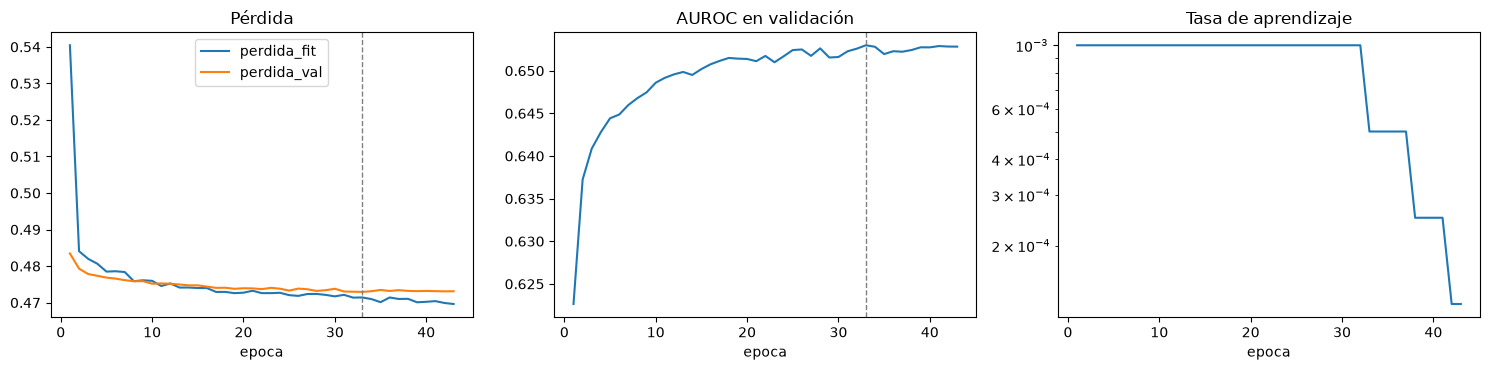

In [8]:
fila_base, modelo_base, historia_base = probar({}, "BASE")
print(f"AUROC validación: {fila_base['auroc']:.4f} · mejor época {fila_base['mejor_epoca']} "
      f"de {fila_base['epocas']} · {fila_base['segundos']} s")

fig, ejes = plt.subplots(1, 3, figsize=(15, 3.8))
historia_base.plot(x="epoca", y=["perdida_fit", "perdida_val"], ax=ejes[0], title="Pérdida")
historia_base.plot(x="epoca", y="auroc_val", ax=ejes[1], title="AUROC en validación", legend=False)
historia_base.plot(x="epoca", y="lr", ax=ejes[2], title="Tasa de aprendizaje", legend=False, logy=True)
for eje in ejes[:2]:
    eje.axvline(fila_base["mejor_epoca"], color="grey", ls="--", lw=1)
plt.tight_layout()

## Paso 7. Comparar los cuatro tipos de red

Las cuatro arquitecturas con el resto de `BASE` igual. Es una comparación
justa en el sentido de que ninguna tiene sus hiperparámetros afinados todavía;
el paso 8 los afina.

Revisar primero la fila `logistica`: debe quedar cerca de 0,646 (la regresión
logística del benchmark). Si queda muy por debajo, hay un problema en el ciclo
de entrenamiento, no en las redes.

In [9]:
resultados_arq, historias_arq = [], {}
for nombre in ARQUITECTURAS:
    fila, _, historia = probar({"arquitectura": nombre}, nombre)
    resultados_arq.append(fila)
    historias_arq[nombre] = historia
    print(f"  {nombre:10} AUROC {fila['auroc']:.4f} · {fila['pesos']:>6,} pesos · {fila['segundos']} s")

tabla_arq = pd.DataFrame(resultados_arq).set_index("etiqueta").drop(columns="cfg")
tabla_arq.round(4)

  logistica  AUROC 0.6479 ·     18 pesos · 0.7 s


  mlp        AUROC 0.6530 ·  1,121 pesos · 2.7 s


  resmlp     AUROC 0.6505 ·  4,833 pesos · 1.8 s


  wide_deep  AUROC 0.6541 ·  1,139 pesos · 2.7 s


,auroc,auprc,brier,calibration_intercept,calibration_slope,mejor_epoca,epocas,pesos,segundos
etiqueta,,,,,,,,,
logistica,0.6479,0.3015,0.1559,-0.1482,1.2060,12,22,18,0.7
mlp,0.6530,0.3238,0.1509,-0.0495,0.9609,33,43,1121,2.7
resmlp,0.6505,0.3197,0.1516,-0.1647,0.9532,8,18,4833,1.8
wide_deep,0.6541,0.3188,0.1513,-0.0706,0.9407,29,39,1139,2.7


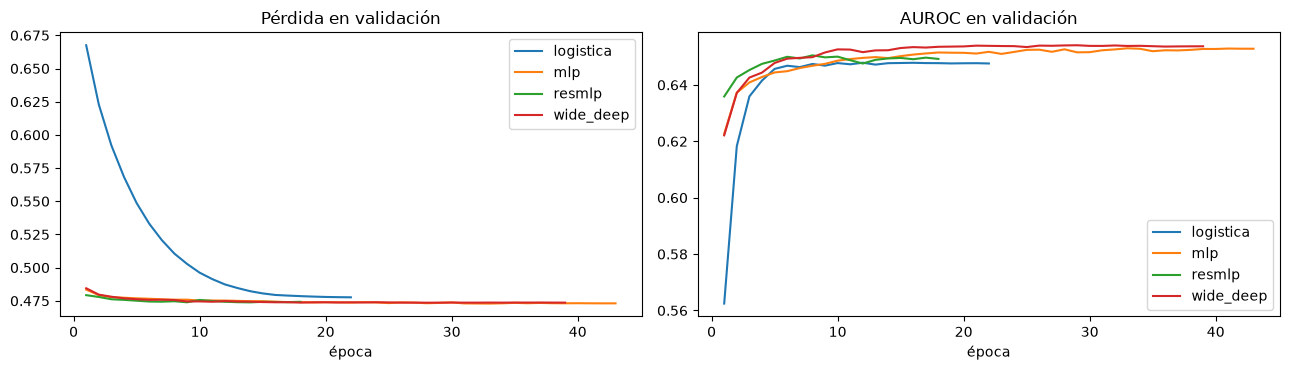

In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 3.8))
for nombre, historia in historias_arq.items():
    ejes[0].plot(historia["epoca"], historia["perdida_val"], label=nombre)
    ejes[1].plot(historia["epoca"], historia["auroc_val"], label=nombre)
ejes[0].set_title("Pérdida en validación")
ejes[1].set_title("AUROC en validación")
for eje in ejes:
    eje.set_xlabel("época")
    eje.legend()
plt.tight_layout()

## Paso 8. Un hiperparámetro a la vez

Se parte de `BASE` y se cambia **un solo** hiperparámetro, dejando todo lo demás
igual. Así se ve el efecto de cada uno por separado: cuáles mueven el AUROC y
cuáles casi no importan. Eso decide dónde vale la pena buscar en el paso 9.

La línea punteada de cada gráfico es `BASE`.

Dos casos para mirar con cuidado:

- **`pos_weight`:** darle más peso a los que vendieron (4 ≈ 80 / 20) suele
  dejar el AUROC casi igual, porque el AUROC solo mira el orden, pero
  **descalibra** las probabilidades (sube el Brier y aleja la recta de
  calibración de 0 y 1). La app compara cada persona con el promedio, así que
  la calibración importa.
- **`lr` con `sgd`:** SGD suele necesitar tasas de aprendizaje más altas que
  Adam; en esta prueba usa la misma de `BASE`, así que puede quedar en
  desventaja.

In [11]:
VARIACIONES = {
    "lr": [1e-4, 3e-4, 1e-3, 3e-3, 1e-2],
    "batch_size": [64, 256, 1024],
    "capas": [(8,), (32,), (32, 16), (64, 32), (128, 64, 32)],
    "dropout": [0.0, 0.1, 0.3, 0.5],
    "weight_decay": [0.0, 1e-4, 1e-3, 1e-2],
    "activacion": ["relu", "gelu", "silu", "tanh"],
    "optimizador": ["adam", "adamw", "sgd"],
    "batchnorm": [False, True],
    "pos_weight": [1.0, 4.0],
}
if RAPIDO:  # solo los extremos
    VARIACIONES = {k: [v[0], v[-1]] for k, v in VARIACIONES.items()}

resultados_factor = []
for parametro, valores in VARIACIONES.items():
    for valor in valores:
        fila, _, _ = probar({parametro: valor}, f"{parametro}={valor}")
        resultados_factor.append({"parametro": parametro, "valor": str(valor), **fila})
        print(f"  {parametro:13} = {str(valor):15} AUROC {fila['auroc']:.4f} "
              f"Brier {fila['brier']:.4f} · {fila['epocas']:>3} épocas")

tabla_factor = pd.DataFrame(resultados_factor)

  lr            = 0.0001          AUROC 0.6489 Brier 0.1518 · 100 épocas


  lr            = 0.0003          AUROC 0.6515 Brier 0.1514 ·  64 épocas


  lr            = 0.001           AUROC 0.6530 Brier 0.1509 ·  43 épocas


  lr            = 0.003           AUROC 0.6523 Brier 0.1513 ·  22 épocas


  lr            = 0.01            AUROC 0.6557 Brier 0.1510 ·  36 épocas


  batch_size    = 64              AUROC 0.6532 Brier 0.1510 ·  27 épocas


... (22 outputs left out)

  batchnorm     = False           AUROC 0.6530 Brier 0.1509 ·  43 épocas


  batchnorm     = True            AUROC 0.6512 Brier 0.1516 ·  28 épocas


  pos_weight    = 1.0             AUROC 0.6530 Brier 0.1509 ·  43 épocas


  pos_weight    = 4.0             AUROC 0.6517 Brier 0.2306 ·  28 épocas


,min,max,rango
parametro,,,
lr,0.6489,0.6557,0.0068
capas,0.6488,0.6545,0.0056
optimizador,0.6480,0.6530,0.0050
weight_decay,0.6493,0.6531,0.0038
dropout,0.6505,0.6530,0.0025
batch_size,0.6508,0.6532,0.0024
activacion,0.6523,0.6544,0.0020
batchnorm,0.6512,0.6530,0.0018
pos_weight,0.6517,0.6530,0.0013


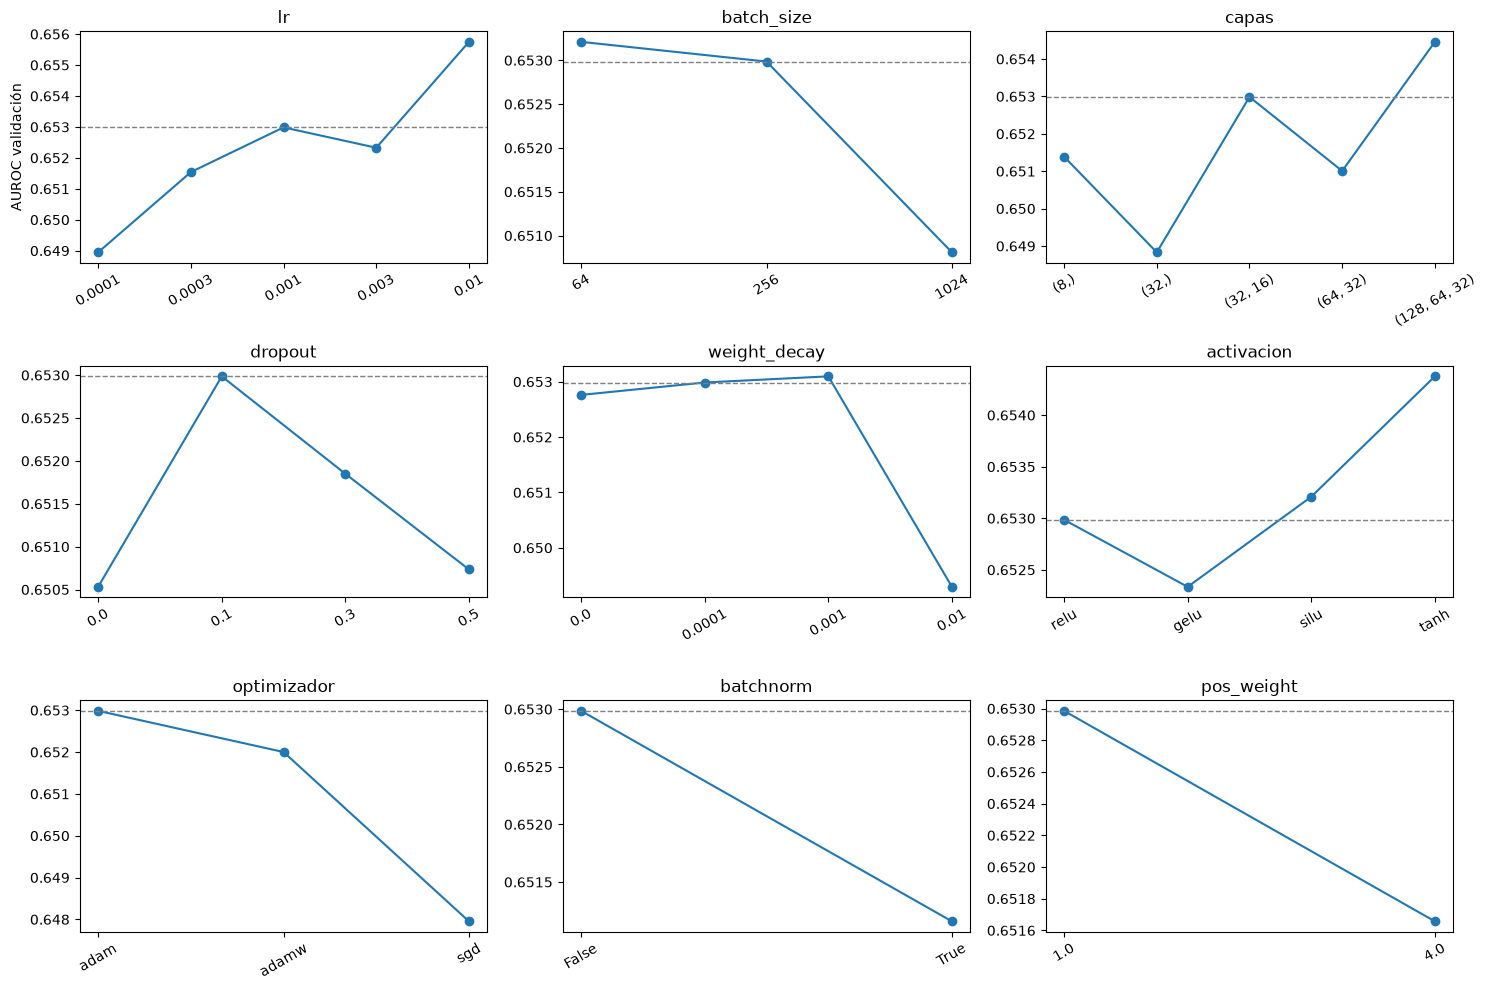

In [12]:
fig, ejes = plt.subplots(3, 3, figsize=(15, 10))
for eje, (parametro, grupo) in zip(ejes.flat, tabla_factor.groupby("parametro", sort=False)):
    eje.plot(grupo["valor"], grupo["auroc"], marker="o")
    eje.axhline(fila_base["auroc"], color="grey", ls="--", lw=1)
    eje.set_title(parametro)
    eje.tick_params(axis="x", rotation=30)
ejes[0, 0].set_ylabel("AUROC validación")
plt.tight_layout()

# Cuánto mueve cada hiperparámetro el AUROC (máximo - mínimo de sus valores).
(tabla_factor.groupby("parametro")["auroc"].agg(["min", "max"])
 .assign(rango=lambda t: t["max"] - t["min"]).sort_values("rango", ascending=False).round(4))

## Paso 9. Búsqueda aleatoria combinando hiperparámetros

El paso 8 no ve interacciones (por ejemplo, una red grande puede necesitar más
dropout). Probar todas las combinaciones sería una rejilla de decenas de miles
de entrenamientos, así que se usa **búsqueda aleatoria**: se sortean `N`
configuraciones del espacio de abajo. Con el mismo presupuesto, la búsqueda
aleatoria suele encontrar mejores configuraciones que una rejilla
(Bergstra y Bengio, 2012), porque no gasta pruebas en los hiperparámetros que
no importan.

El espacio deja fuera lo que el paso 8 mostró que estorba o no aporta
(`pos_weight` alto, `sgd`); ajústalo si tus resultados del paso 8 dicen otra
cosa.

In [13]:
ESPACIO = {
    "arquitectura": ["mlp", "resmlp", "wide_deep"],
    "capas": [(16,), (32,), (64,), (32, 16), (64, 32), (128, 64)],
    "ancho": [16, 32, 64],
    "n_bloques": [1, 2, 3],
    "activacion": ["relu", "gelu", "silu"],
    "dropout": [0.0, 0.1, 0.2, 0.3],
    "batchnorm": [False, True],
    "optimizador": ["adam", "adamw"],
    "lr": [3e-4, 1e-3, 3e-3],
    "weight_decay": [0.0, 1e-4, 1e-3, 1e-2],
    "batch_size": [128, 256, 512],
}
N_PRUEBAS = 6 if RAPIDO else 30

sorteo = np.random.default_rng(RANDOM_STATE)


def sortear_configuracion():
    return {k: v[sorteo.integers(len(v))] for k, v in ESPACIO.items()}


resultados_busqueda = []
for i in range(1, N_PRUEBAS + 1):
    cfg = sortear_configuracion()
    fila, _, _ = probar(cfg, f"prueba_{i:02d}")
    resultados_busqueda.append(fila)
    print(f"  {i:2d}/{N_PRUEBAS} {cfg['arquitectura']:9} AUROC {fila['auroc']:.4f} · "
          f"{fila['pesos']:>6,} pesos · {fila['segundos']} s")

tabla_busqueda = (pd.DataFrame(resultados_busqueda)
                  .sort_values("auroc", ascending=False).reset_index(drop=True))

   1/30 mlp       AUROC 0.6523 ·  3,265 pesos · 5.8 s


   2/30 wide_deep AUROC 0.6536 ·  3,283 pesos · 4.9 s


   3/30 mlp       AUROC 0.6525 · 11,009 pesos · 9.3 s


   4/30 resmlp    AUROC 0.6526 ·  2,065 pesos · 5.5 s


   5/30 mlp       AUROC 0.6545 · 11,009 pesos · 11.0 s


   6/30 mlp       AUROC 0.6538 ·  1,217 pesos · 7.5 s


... (20 outputs left out)

  27/30 mlp       AUROC 0.6539 ·  1,217 pesos · 2.5 s


  28/30 resmlp    AUROC 0.6461 ·  1,489 pesos · 7.1 s


  29/30 mlp       AUROC 0.6535 ·    305 pesos · 0.7 s


  30/30 wide_deep AUROC 0.6522 ·    627 pesos · 3.9 s


In [14]:
# Las 10 mejores, con los hiperparámetros que las definen.
def resumen_cfg(cfg):
    tam = ({"capas": cfg["capas"]} if cfg["arquitectura"] != "resmlp"
           else {"ancho": cfg["ancho"], "n_bloques": cfg["n_bloques"]})
    claves = ["arquitectura", "activacion", "dropout", "batchnorm", "optimizador", "lr",
              "weight_decay", "batch_size"]
    return {**{k: cfg[k] for k in claves[:1]}, **tam, **{k: cfg[k] for k in claves[1:]}}


top = tabla_busqueda.head(10)
pd.concat([top[["etiqueta", "auroc", "auprc", "brier", "mejor_epoca", "pesos"]],
           pd.DataFrame([resumen_cfg(c) for c in top["cfg"]])], axis=1).round(4)

,etiqueta,auroc,auprc,brier,mejor_epoca,pesos,arquitectura,capas,activacion,dropout,batchnorm,optimizador,lr,weight_decay,batch_size,ancho,n_bloques
0,prueba_05,0.6545,0.3234,0.1510,29,11009,mlp,"(128, 64)",silu,0.3,True,adam,0.0010,0.0001,256,NaN,NaN
1,prueba_27,0.6539,0.3216,0.1513,18,1217,mlp,"(32, 16)",silu,0.1,True,adam,0.0010,0.0010,512,NaN,NaN
2,prueba_06,0.6538,0.3212,0.1511,15,1217,mlp,"(32, 16)",silu,0.3,True,adam,0.0030,0.0001,128,NaN,NaN
3,prueba_18,0.6536,0.3237,0.1510,75,1937,resmlp,NaN,gelu,0.2,False,adamw,0.0003,0.0001,128,16.0,3.0
4,prueba_02,0.6536,0.3197,0.1512,29,3283,wide_deep,"(64, 32)",silu,0.2,False,adamw,0.0010,0.0010,256,NaN,NaN
5,prueba_29,0.6535,0.3166,0.1514,17,305,mlp,"(16,)",relu,0.1,False,adamw,0.0030,0.0010,512,NaN,NaN
6,prueba_22,0.6531,0.3192,0.1513,27,323,wide_deep,"(16,)",silu,0.2,False,adam,0.0010,0.0000,256,NaN,NaN
7,prueba_20,0.6526,0.3184,0.1513,64,627,wide_deep,"(32,)",gelu,0.2,False,adam,0.0003,0.0001,512,NaN,NaN
8,prueba_04,0.6526,0.3230,0.1510,8,2065,resmlp,NaN,silu,0.1,True,adam,0.0030,0.0010,256,16.0,3.0
9,prueba_15,0.6526,0.3180,0.1515,21,1489,resmlp,NaN,gelu,0.3,True,adamw,0.0010,0.0001,256,16.0,2.0


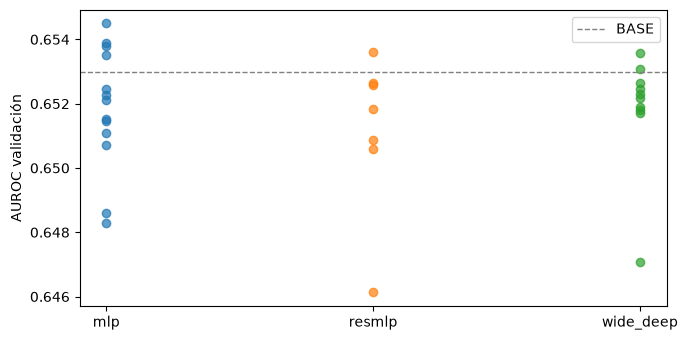

In [15]:
# ¿Alguna arquitectura domina? AUROC de cada prueba, por tipo de red.
arq = tabla_busqueda["cfg"].map(lambda c: c["arquitectura"])
fig, eje = plt.subplots(figsize=(7, 3.5))
for i, (nombre, grupo) in enumerate(tabla_busqueda.groupby(arq)):
    eje.scatter([i] * len(grupo), grupo["auroc"], alpha=0.7)
eje.set_xticks(range(arq.nunique()), sorted(arq.unique()))
eje.axhline(fila_base["auroc"], color="grey", ls="--", lw=1, label="BASE")
eje.set_ylabel("AUROC validación")
eje.legend()
plt.tight_layout()

## Paso 10. Validación cruzada de las mejores configuraciones

Hasta aquí todo se midió en **una** sola validación de 8.753 personas. Con un
AUROC alrededor de 0,65, la diferencia entre configuraciones es de milésimas, y
una sola partición puede premiar a una configuración por suerte.

Este paso mide las candidatas con las **mismas 5 particiones externas de
`evaluate_model`** (`StratifiedKFold(5, shuffle=True, random_state=42)` sobre
`X_train`), para que el resultado se pueda poner al lado del benchmark. En cada
partición:

1. Las 4 / 5 de entrenamiento se dividen en ajuste (90 %) y una validación
   interna (10 %) que solo sirve para el early stopping.
2. El escalador se ajusta con la parte de ajuste.
3. La red se mide en la quinta parte que no vio.

Candidatas: la regresión logística en PyTorch (control), `BASE` y las 3 mejores
de la búsqueda.

> **Ojo:** las 3 mejores se eligieron mirando la validación del paso 2, que es
> parte de `X_train`; su promedio aquí es **un poco optimista**. El paso 11
> corrige eso.

In [16]:
EXTERNAS = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)  # las de evaluate_model


def validacion_cruzada(cfg, X, y, particiones=EXTERNAS):
    # Mide cfg en las 5 particiones. Devuelve una fila de métricas por partición.
    filas = []
    for k, (idx_ent, idx_med) in enumerate(particiones.split(X, y), start=1):
        X_ent, y_ent = X.iloc[idx_ent], y.iloc[idx_ent]
        X_aj, X_es, y_aj, y_es = train_test_split(
            X_ent, y_ent, test_size=0.1, stratify=y_ent, random_state=RANDOM_STATE)
        scaler = StandardScaler().fit(X_aj)

        def t(M):
            return torch.tensor(scaler.transform(M), dtype=torch.float32, device=DEVICE)

        def ty(v):
            return torch.tensor(np.asarray(v), dtype=torch.float32, device=DEVICE)

        modelo, _ = entrenar(cfg, t(X_aj), ty(y_aj), t(X_es), ty(y_es))
        filas.append({"particion": k, **metricas(y.iloc[idx_med], predecir(modelo, t(X.iloc[idx_med])))})
    return pd.DataFrame(filas)


CANDIDATAS = {
    "pytorch_logistica": {"arquitectura": "logistica"},
    "pytorch_base": {},
    **{f"pytorch_top{i + 1}": cfg for i, cfg in enumerate(tabla_busqueda["cfg"].head(3))},
}

resultados_cv, filas_cv = {}, []
for nombre, cfg in CANDIDATAS.items():
    inicio = time.perf_counter()
    por_particion = validacion_cruzada(cfg, X_train, y_train)
    resultados_cv[nombre] = por_particion
    fila = {"model": nombre}
    for m in ["auroc", "auprc", "brier", "calibration_intercept", "calibration_slope"]:
        fila[m], fila[f"{m}_sd"] = por_particion[m].mean(), por_particion[m].std(ddof=0)
    filas_cv.append(fila)
    print(f"  {nombre:18} AUROC {fila['auroc']:.4f} ± {fila['auroc_sd']:.4f} "
          f"· {time.perf_counter() - inicio:.0f} s")

tabla_cv = pd.DataFrame(filas_cv)

  pytorch_logistica  AUROC 0.6441 ± 0.0034 · 3 s


  pytorch_base       AUROC 0.6506 ± 0.0054 · 10 s


  pytorch_top1       AUROC 0.6544 ± 0.0035 · 28 s


  pytorch_top2       AUROC 0.6514 ± 0.0070 · 12 s


  pytorch_top3       AUROC 0.6531 ± 0.0021 · 27 s


## Paso 11. (Opcional) Validación anidada: el número honesto

Para que el AUROC de la red sea comparable **de verdad** con el benchmark, la
búsqueda de hiperparámetros tiene que repetirse **dentro** de cada partición
externa, sin ver nunca la quinta parte con la que se mide. Es lo mismo que hace
`evaluate_model` con `GridSearchCV`, pero con la búsqueda aleatoria del paso 9:

```
para cada una de las 5 particiones externas:
    entrenamiento externo  ->  ajuste (80 %) + validación interna (20 %)
    sortear N_ANIDADA configuraciones, entrenarlas en ajuste, medirlas en validación interna
    la mejor se reentrena (ajuste + early stopping) y se mide en la partición externa
```

Cuesta `5 × N_ANIDADA` entrenamientos; se apaga con `VALIDACION_ANIDADA` en el
paso 0.

In [17]:
N_ANIDADA = 4 if RAPIDO else 15

if VALIDACION_ANIDADA:
    filas_anidada, elegidas = [], []
    for k, (idx_ent, idx_med) in enumerate(EXTERNAS.split(X_train, y_train), start=1):
        X_ent, y_ent = X_train.iloc[idx_ent], y_train.iloc[idx_ent]
        X_aj, X_in, y_aj, y_in = train_test_split(
            X_ent, y_ent, test_size=0.2, stratify=y_ent, random_state=RANDOM_STATE)
        scaler = StandardScaler().fit(X_aj)

        def t(M):
            return torch.tensor(scaler.transform(M), dtype=torch.float32, device=DEVICE)

        def ty(v):
            return torch.tensor(np.asarray(v), dtype=torch.float32, device=DEVICE)

        # búsqueda interna: misma semilla de sorteo en cada partición
        sorteo = np.random.default_rng(RANDOM_STATE)
        mejor_auc, mejor_modelo, mejor_cfg = -np.inf, None, None
        for _ in range(N_ANIDADA):
            cfg = sortear_configuracion()
            modelo, _ = entrenar(cfg, t(X_aj), ty(y_aj), t(X_in), ty(y_in))
            auc = roc_auc_score(y_in, predecir(modelo, t(X_in)))
            if auc > mejor_auc:
                mejor_auc, mejor_modelo, mejor_cfg = auc, modelo, cfg

        m = metricas(y_train.iloc[idx_med], predecir(mejor_modelo, t(X_train.iloc[idx_med])))
        filas_anidada.append({"particion": k, **m})
        elegidas.append(resumen_cfg({**BASE, **mejor_cfg}))
        print(f"  partición {k}: AUROC {m['auroc']:.4f} · elegida: {elegidas[-1]}")

    anidada = pd.DataFrame(filas_anidada)
    fila = {"model": "pytorch_anidada"}
    for m in ["auroc", "auprc", "brier", "calibration_intercept", "calibration_slope"]:
        fila[m], fila[f"{m}_sd"] = anidada[m].mean(), anidada[m].std(ddof=0)
    tabla_cv = pd.concat([tabla_cv[tabla_cv["model"] != "pytorch_anidada"], pd.DataFrame([fila])],
                         ignore_index=True)
    print(f"\nAUROC anidado: {fila['auroc']:.4f} ± {fila['auroc_sd']:.4f}")
else:
    print("Validación anidada apagada (VALIDACION_ANIDADA = False).")

  partición 1: AUROC 0.6476 · elegida: {'arquitectura': 'resmlp', 'ancho': 16, 'n_bloques': 3, 'activacion': 'silu', 'dropout': 0.1, 'batchnorm': True, 'optimizador': 'adam', 'lr': 0.003, 'weight_decay': 0.001, 'batch_size': 256}


  partición 2: AUROC 0.6566 · elegida: {'arquitectura': 'mlp', 'capas': (32, 16), 'activacion': 'silu', 'dropout': 0.3, 'batchnorm': True, 'optimizador': 'adam', 'lr': 0.003, 'weight_decay': 0.0001, 'batch_size': 128}


  partición 3: AUROC 0.6519 · elegida: {'arquitectura': 'mlp', 'capas': (32, 16), 'activacion': 'silu', 'dropout': 0.3, 'batchnorm': True, 'optimizador': 'adam', 'lr': 0.003, 'weight_decay': 0.0001, 'batch_size': 128}


  partición 4: AUROC 0.6577 · elegida: {'arquitectura': 'mlp', 'capas': (32, 16), 'activacion': 'silu', 'dropout': 0.3, 'batchnorm': True, 'optimizador': 'adam', 'lr': 0.003, 'weight_decay': 0.0001, 'batch_size': 128}


  partición 5: AUROC 0.6546 · elegida: {'arquitectura': 'mlp', 'capas': (128, 64), 'activacion': 'silu', 'dropout': 0.3, 'batchnorm': True, 'optimizador': 'adam', 'lr': 0.001, 'weight_decay': 0.0001, 'batch_size': 256}

AUROC anidado: 0.6537 ± 0.0036


## Paso 12. Comparación con el benchmark y conclusiones

Se ponen las redes de PyTorch al lado de los modelos de `reports/benchmark.csv`
(validación anidada 5 × 3, protocolo) y de la mejor red de scikit-learn en
`reports/experiments.csv` (rejilla ampliada).

Para leer la tabla:

- **AUROC ± desviación:** la regla del ganador del protocolo dice que si un
  modelo más simple queda a menos de una desviación estándar del mejor, gana el
  más simple.
- **Brier** (más bajo es mejor) y **calibración** (intercepto ≈ 0, pendiente ≈ 1):
  dicen si las probabilidades se pueden leer como probabilidades.
- Las filas `pytorch_top*` son algo optimistas (paso 10); la comparable de
  verdad con el benchmark es `pytorch_anidada` (paso 11).

In [18]:
cols = ["model", "auroc", "auroc_sd", "auprc", "brier", "calibration_intercept", "calibration_slope"]
benchmark = pd.read_csv(REPORTS_DIR / "benchmark.csv")
benchmark["origen"] = "benchmark (anidada)"

experimentos = pd.read_csv(REPORTS_DIR / "experiments.csv")
mejor_sklearn = (experimentos[experimentos["model"] == "neural_net"]
                 .sort_values("auroc", ascending=False).head(1)
                 .assign(model="sklearn_mlp_mejor", origen="experiments.csv (anidada)"))

pytorch = tabla_cv.assign(
    origen=np.where(tabla_cv["model"] == "pytorch_anidada", "este notebook (anidada)",
                    "este notebook (5 particiones)"))

comparacion = (pd.concat([benchmark[cols + ["origen"]], mejor_sklearn[cols + ["origen"]],
                          pytorch[cols + ["origen"]]], ignore_index=True)
               .sort_values("auroc", ascending=False).reset_index(drop=True))
comparacion.round(4)

,model,auroc,auroc_sd,auprc,brier,calibration_intercept,calibration_slope,origen
0,catboost,0.6613,0.0039,0.3320,0.1502,0.1280,1.0956,benchmark (anidada)
1,xgboost,0.6601,0.0035,0.3307,0.1503,0.0738,1.0556,benchmark (anidada)
2,lightgbm,0.6600,0.0036,0.3306,0.1503,0.0725,1.0546,benchmark (anidada)
3,random_forest,0.6573,0.0037,0.3304,0.1507,0.3024,1.2284,benchmark (anidada)
4,pytorch_top1,0.6544,0.0035,0.3248,0.1513,-0.1427,0.9714,este notebook (5 particiones)
5,pytorch_anidada,0.6537,0.0036,0.3226,0.1511,-0.0183,1.0095,este notebook (anidada)
6,pytorch_top3,0.6531,0.0021,0.3224,0.1513,0.0733,1.0775,este notebook (5 particiones)
7,pytorch_top2,0.6514,0.0070,0.3205,0.1516,-0.1084,0.9758,este notebook (5 particiones)
8,pytorch_base,0.6506,0.0054,0.3218,0.1512,-0.0285,0.9749,este notebook (5 particiones)
9,sklearn_mlp_mejor,0.6504,0.0033,0.3210,0.1514,-0.1194,0.9257,experiments.csv (anidada)


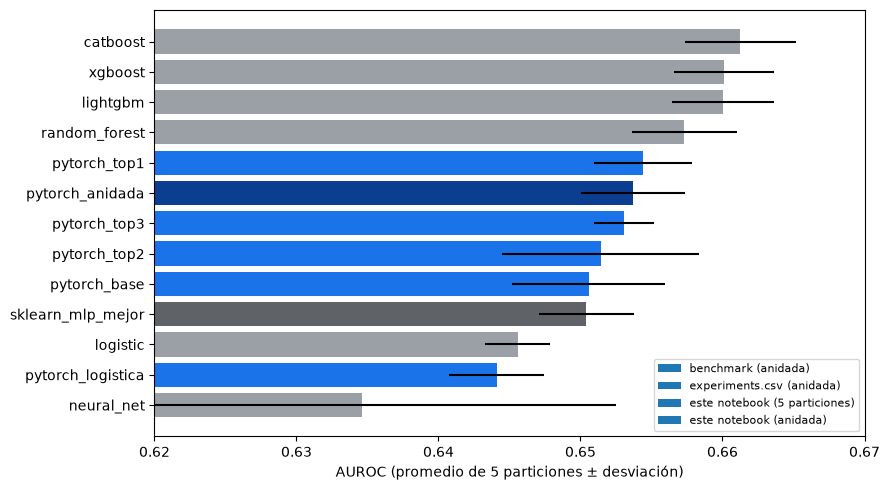

In [19]:
fig, eje = plt.subplots(figsize=(9, 5))
colores = {"benchmark (anidada)": "#9aa0a6", "experiments.csv (anidada)": "#5f6368",
           "este notebook (5 particiones)": "#1a73e8", "este notebook (anidada)": "#0b3d91"}
orden = comparacion[comparacion["model"] != "trivial"].iloc[::-1]
eje.barh(orden["model"], orden["auroc"], xerr=orden["auroc_sd"],
         color=orden["origen"].map(colores))
eje.set_xlim(0.62, 0.67)
eje.set_xlabel("AUROC (promedio de 5 particiones ± desviación)")
for origen, color in colores.items():
    eje.barh([], [], color=color, label=origen)
eje.legend(loc="lower right", fontsize=8)
plt.tight_layout()

In [20]:
if GUARDAR:
    REPORTS_DIR.mkdir(exist_ok=True)
    guardar = pd.concat([
        tabla_arq.reset_index().assign(etapa="7_arquitecturas"),
        tabla_factor.drop(columns="cfg").assign(etapa="8_un_factor"),
        tabla_busqueda.assign(cfg=tabla_busqueda["cfg"].map(str)).assign(etapa="9_busqueda"),
        tabla_cv.rename(columns={"model": "etiqueta"}).assign(etapa="10_11_validacion_cruzada"),
    ], ignore_index=True)
    guardar.to_csv(RESULTS_FILE, index=False)
    print(f"{len(guardar)} filas guardadas en {RESULTS_FILE.relative_to(RAIZ)}")

72 filas guardadas en reports/pytorch_experiments.csv


### Conclusiones

Corrida completa del 15-11-2026 (`RAPIDO = False`, `VALIDACION_ANIDADA = True`).

1. **El ciclo de entrenamiento está bien.** La regresión logística en PyTorch dio
   AUROC 0,644 ± 0,003, frente a 0,646 ± 0,002 de scikit-learn. Su calibración
   sí quedó peor (Brier 0,168, intercepto −0,36), porque el early stopping mira
   el AUROC: el orden de las personas se estabiliza en pocas épocas, antes de que
   el intercepto termine de ajustarse. Es una advertencia general: **parar por
   AUROC no garantiza probabilidades calibradas**.
2. **El tipo de red casi no importa.** En el paso 7, MLP, ResMLP y Wide & Deep
   quedaron entre 0,650 y 0,654. En la búsqueda del paso 9, las 30 pruebas
   quedaron entre 0,646 y 0,655, mezcladas sin que ninguna arquitectura domine.
3. **Lo que más mueve el AUROC** (paso 8) es la tasa de aprendizaje (rango
   0,007), el tamaño de las capas (0,006) y el optimizador: SGD con la tasa de
   Adam quedó atrás (0,648). Dropout, batch norm, activación y tamaño de lote
   mueven menos de 0,003. `pos_weight = 4` no mejora el AUROC y descalibra todo
   (Brier 0,151 → 0,231): no conviene usarlo.
4. **PyTorch sí le gana a la red de scikit-learn.** El número honesto (validación
   anidada) es **0,654 ± 0,004**, frente a 0,650 de la mejor red de
   `experiments.csv` y 0,635 de la red del benchmark, con buena calibración
   (intercepto −0,02, pendiente 1,01). En 4 de 5 particiones la búsqueda eligió un
   MLP con SiLU, dropout 0,3 y batch norm (en 3 de ellas, de capas 32 y 16).
5. **Pero no alcanza a los árboles.** CatBoost tiene 0,661 ± 0,004. La red
   queda 0,008 abajo, más de una desviación estándar, y también por debajo de
   Random Forest (0,657). La conclusión del benchmark se sostiene: con 17
   variables de un cuestionario, los árboles con boosting aprovechan mejor los
   datos, y la red no justifica su costo en entrenamiento y explicabilidad.
6. **Calibración.** La red anidada está tan bien calibrada como los boosting
   (Brier 0,1511 frente a 0,1502 a 0,1503); la diferencia está en la
   discriminación, no en la calibración.

Todos los resultados quedan en `reports/pytorch_experiments.csv` (columna `etapa`).